11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
학습 데이터: (60000, 28, 28) 시험 데이터: (10000, 28, 28)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 2s - 6ms/step - accuracy: 0.8975 - loss: 0.3711 - val_accuracy: 0.9585 - val_loss: 0.1601
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9516 - loss: 0.1711 - val_accuracy: 0.9663 - val_loss: 0.1220
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9644 - loss: 0.1254 - val_accuracy: 0.9723 - val_loss: 0.1029
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9727 - loss: 0.0974 - val_accuracy: 0.9740 - val_loss: 0.0906
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9774 - loss: 0.0788 - val_accuracy: 0.9743 - val_loss: 0.0862
Epoch 6/10
422/422 - 3s - 8ms/step - accuracy: 0.9811 - loss: 0.0654 - val_accuracy: 0.9775 - val_loss: 0.0830
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9842 - loss: 0.0543 - val_accuracy: 0.9783 - val_loss: 0.0779
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9863 - loss: 0.0469 - val_accuracy: 0.9783 - val_loss: 0.0761
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9890 - loss: 0.0391 - val_accuracy: 0.9767 - val_loss: 0.0768
E

/tmp/ipykernel_1850/1101424993.py:65: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1850/1101424993.py:65: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1850/1101424993.py:65: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1850/1101424993.py:65: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3

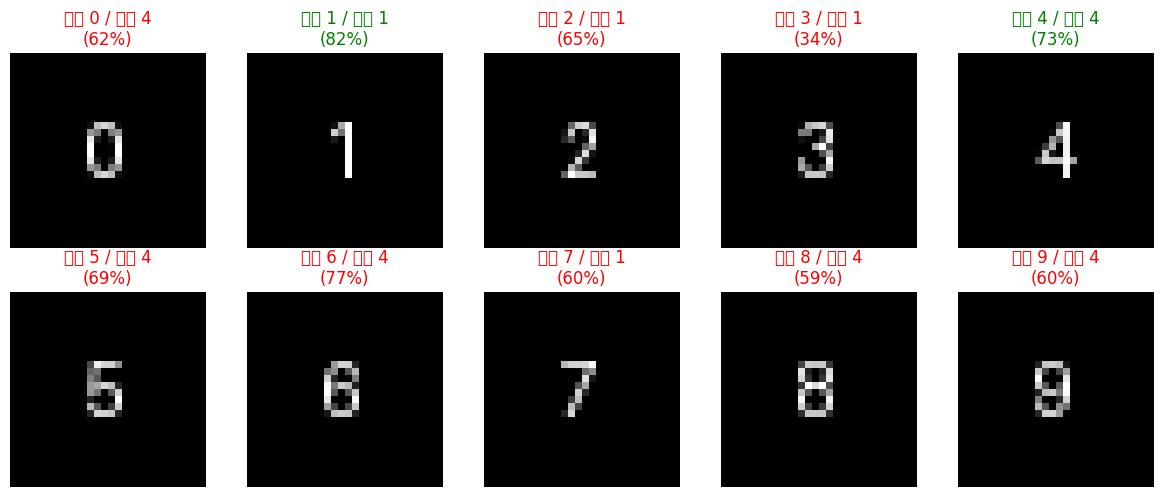

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image, ImageDraw, ImageFont

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("학습 데이터:", x_train.shape, "시험 데이터:", x_test.shape)

x_train = x_train / 255.0
x_test = x_test / 255.0

model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

history = model.fit(x_train, y_train,
                    epochs=10, batch_size=128,
                    validation_split=0.1, verbose=2)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nMNIST 시험 데이터 정확도: {test_acc*100:.2f}%")

def make_digit_image(d, size=28):
    """검정 배경 + 흰색 숫자 (MNIST와 같은 형태)"""
    img = Image.new('L', (size, size), 0)
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 28)
    except OSError:
        font = ImageFont.load_default()
    box = draw.textbbox((0, 0), str(d), font=font)
    w, h = box[2] - box[0], box[3] - box[1]
    draw.text(((size - w) / 2 - box[0], (size - h) / 2 - box[1]),
              str(d), fill=255, font=font)
    return np.array(img) / 255.0

my_imgs = np.array([make_digit_image(d) for d in range(10)])
my_labels = np.arange(10)

probs = model.predict(my_imgs, verbose=0)
pred = probs.argmax(axis=1)

print("정답:", my_labels.tolist())
print("예측:", pred.tolist())
print(f"내 이미지 정확도: {(pred == my_labels).mean()*100:.0f}% "
      f"({(pred == my_labels).sum()}/10)")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(my_imgs[i], cmap='gray')
    ok = pred[i] == my_labels[i]
    ax.set_title(f"정답 {my_labels[i]} / 예측 {pred[i]}\n({probs[i].max()*100:.0f}%)",
                 color='green' if ok else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()

| 실행 회차 | MNIST 시험 정확도 | 내 이미지 예측값 (정답 0~9) | 맞힌 개수 |
| ----- | ------- | ------------------------------ | ----- |
| 1회 | 97.50% | [4, 1, 1, 1, 4, 4, 4, 1, 4, 4] | 2/10 |
| 2회 | 97.76% | [4, 1, 1, **7**, 4, 4, 4, 1, 4, 4] | 2/10 |
| 3회 | 97.80% | [4, 1, 1, 1, 4, 4, 4, 1, 4, 4] | 2/10 |
 
(맞힌 것은 모든 회차에서 1과 4입니다.)
 
## 값이 변하는 이유
 
실행할 때마다 결과가 조금씩 달라지는 이유는 Dense 레이어의 가중치(w)와 편향(b)이 학습 전에 무작위 값으로 초기화되고, 학습 데이터를 섞어서 미니배치로 나누는 순서도 매번 다르기 때문이다. 경사하강법(Adam)은 이 무작위 시작점에서 손실이 줄어드는 방향으로 이동하므로, 시작점이 다르면 10 epoch만으로는 완전히 같은 지점에 도달하지 못하고 서로 다른 지점에서 멈춘다. 그래서 MNIST 시험 정확도도 97.50%, 97.76%, 97.80%로 약간씩 달랐다.
 
반면 내가 만든 이미지의 예측은 3회 모두 거의 같았다. 2회차에서만 숫자 3의 예측이 1에서 7로 바뀌었다. 직접 만든 이미지는 굵은 폰트가 28×28 칸을 가득 채워서 MNIST 손글씨(20×20 크기, 가장자리 여백 있음)와 모양이 크게 달랐고, 모델이 대부분의 이미지를 1이나 4로 분류했기 때문이다. 학습 때 보지 못한 형태의 입력이라 모델이 일관되게 잘못 판단했고, 모양이 애매한 3처럼 판단 경계에 있는 이미지만 가중치의 작은 차이에 따라 예측이 바뀌었다.
 
매번 같은 결과를 얻고 싶다면 학습 전에 난수 시드를 고정하면 된다.
 
```python
import numpy as np, tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)
```